# Browniano — de las trayectorias de TouchDesigner al coeficiente de difusión

Lee una salida de **PROCESAR** (`trayectorias.csv`, `tiempo.csv`, …), dibuja las trayectorias, **resta la deriva** de cada partícula, separa las beads **libres** de las **atrapadas** y calcula el MSD y D.

- Si B8 tenía *Escala (nm/px)*, todo va en µm; si no, en px.
- El MSD usa los tiempos reales de cada cuadro (`pinzas/libre.py`): $\mathrm{MSD}(\tau) = 4D\tau + 4\sigma^2$, con $\sigma$ el ruido de localización por eje.
- Con una deriva $v$: $\mathrm{MSD} = 4D\tau + v^2\tau^2 + 4\sigma^2$ → hay que restarla antes.

In [1]:
from trayectorias import *

usar_estilo()

CARPETA = ultima_salida()        # o la carpeta de una salida: r"C:\datos_pinzas\...\csv\<fecha>"
LARGO_MIN = 150                  # cuadros medidos: más cortas no entran (ver la deriva por partícula)
MAX_LAG = 40                     # retardo máximo del MSD, en cuadros
N_AJUSTE = 4                     # retardos que se usan para ajustar D
ALFA_ATRAPADA = 0.5              # pendiente log-log del MSD por debajo de la cual una bead está confinada

datos = cargar(CARPETA)
t, X, Y, ids, u = matrices(datos, largo_min=LARGO_MIN)
_, Xp, Yp, idp, _ = matrices(datos, escala_um=0, largo_min=LARGO_MIN)   # en px, para dibujar sobre la imagen
print(CARPETA)
print('%d cuadros, %.1f s, dt = %.4f s | %d partículas con más de %d cuadros (de %d) | unidad: %s'
      % (len(t), t[-1] - t[0], np.median(np.diff(t)), len(ids), LARGO_MIN, datos['tr'].particula.nunique(), u))

C:/datos_pinzas\IMPORTADAS\2026-11-05_151135_importada_recorte_de_laser_y_browniano\csv\2026-11-05_151730
719 cuadros, 52.9 s, dt = 0.0640 s | 20 partículas con más de 150 cuadros (de 40) | unidad: px


## 1. Trayectorias

Sobre el primer cuadro del video. El punto marca dónde empieza cada una.

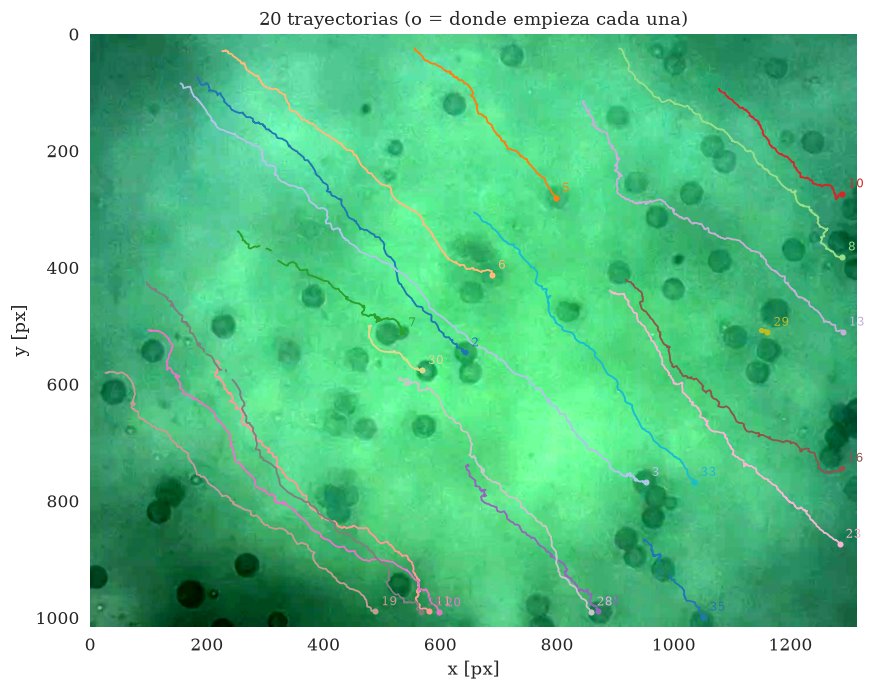

In [2]:
graficar_trayectorias(datos, Xp, Yp, idp);

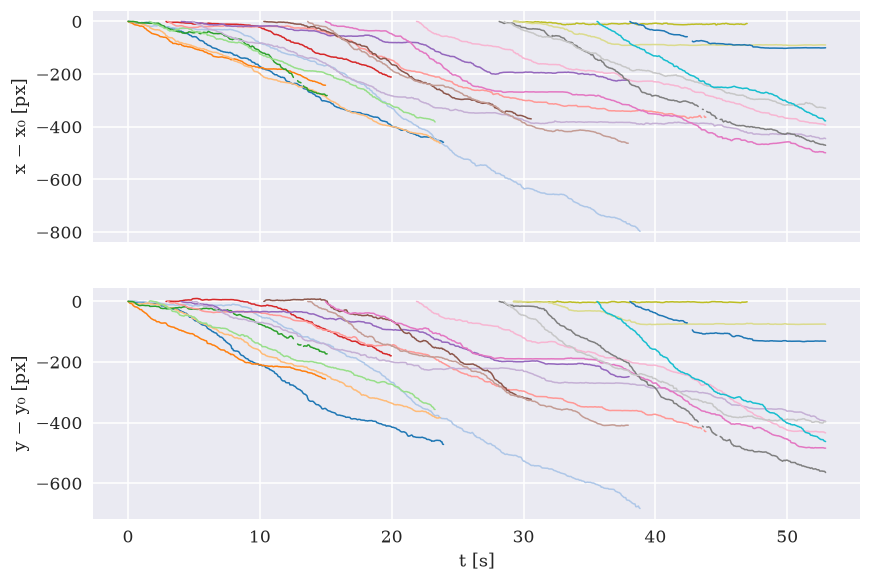

In [3]:
graficar_xy_t(t, X, Y, ids, u);

## 2. Deriva

Las partículas se corren (flujo en la muestra). Si todas derivaran igual alcanzaría con restar la deriva **común** (el promedio). Pero cada una va a su velocidad (beads a distinta altura en un flujo con perfil), así que a cada partícula se le resta **su** recta $x(t)$, $y(t)$.

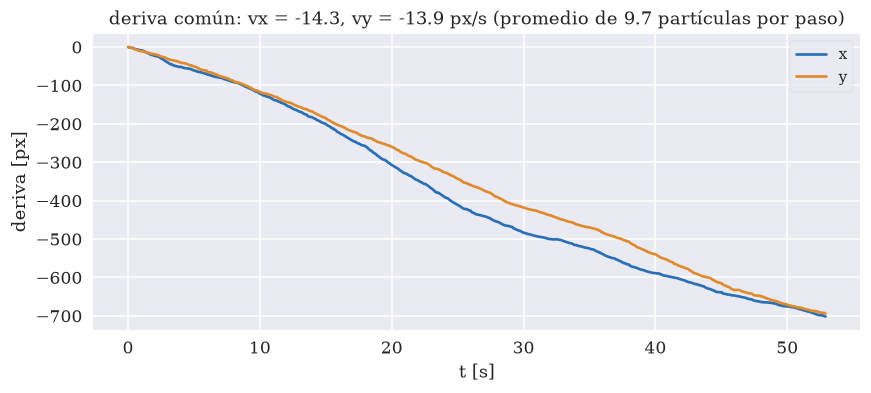

In [4]:
ax, v = graficar_deriva(t, X, Y, u)

|v| por partícula: media 20.2, desvío 9.0 px/s (45 % de la media): la deriva NO es común


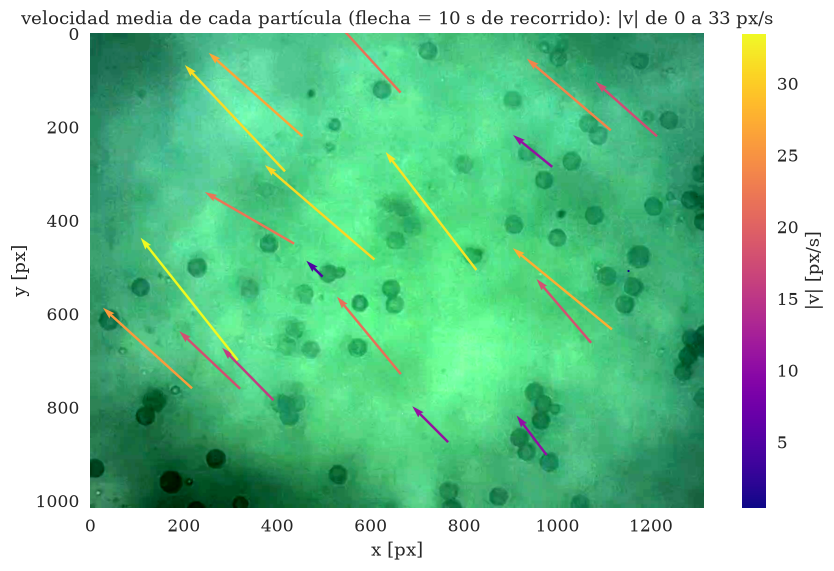

In [5]:
ax, (vx, vy) = graficar_velocidades(datos, t, Xp, Yp)
rap = np.hypot(vx, vy)
print('|v| por partícula: media %.1f, desvío %.1f px/s (%.0f %% de la media): la deriva NO es común'
      % (np.nanmean(rap), np.nanstd(rap), 100 * np.nanstd(rap) / np.nanmean(rap)))

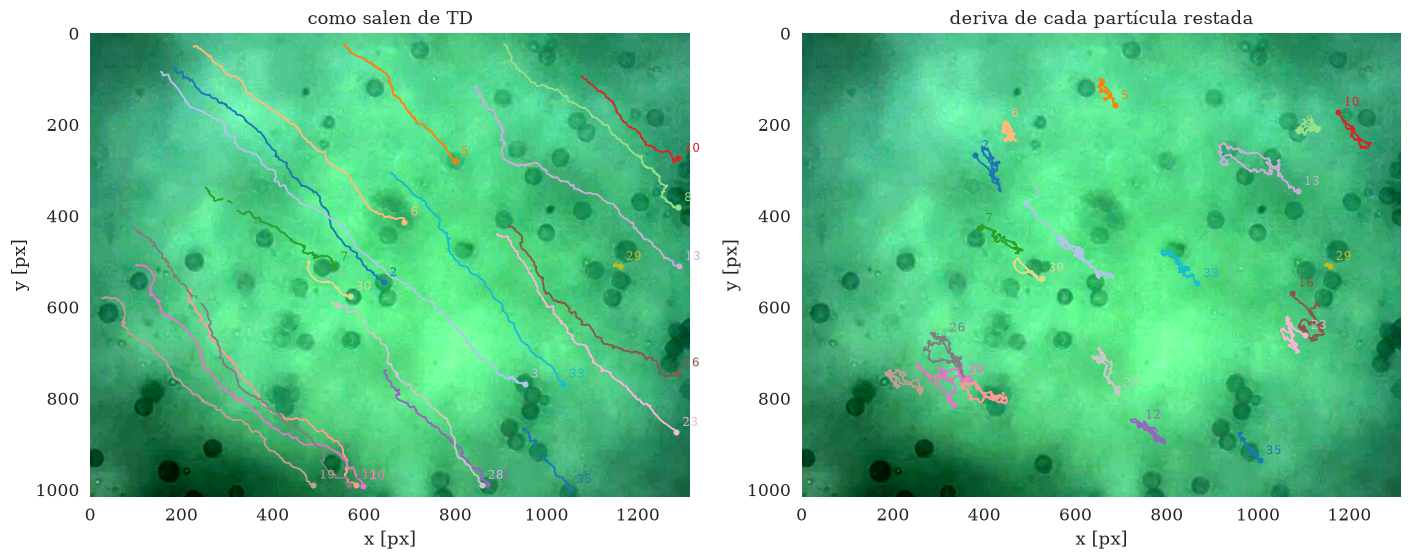

In [6]:
Xc, Yc = sin_deriva(X, Y)                       # deriva común
Xs, Ys = sin_deriva_por_particula(t, X, Y)      # deriva de cada partícula
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
graficar_trayectorias(datos, Xp, Yp, idp, ax=axs[0], titulo='como salen de TD')
Xsp, Ysp = sin_deriva_por_particula(t, Xp, Yp)
graficar_trayectorias(datos, Xsp, Ysp, idp, ax=axs[1], titulo='deriva de cada partícula restada')
plt.tight_layout()

## 3. MSD: libres y atrapadas

Una bead **libre** da pendiente 1 en log-log. Una **atrapada** (en la pinza) da un MSD que se **aplana**: no puede alejarse más que el tamaño de la trampa. Se separan por la pendiente $\alpha$ del MSD a tiempos largos.

In [7]:
m_crudo = msd(t, X, Y, MAX_LAG)
m_comun = msd(t, Xc, Yc, MAX_LAG)
m = msd(t, Xs, Ys, MAX_LAG)
alfa = pendiente_loglog(m)
atrapada = alfa < ALFA_ATRAPADA
tabla = coeficientes_D(m, n_puntos=N_AJUSTE)
tabla.insert(0, 'particula', ids)
tabla['cuadros'] = np.isfinite(X).sum(0)
tabla['v [%s/s]' % u] = rap * (datos['escala_um'] or 1)
tabla['alfa'] = alfa
tabla['atrapada'] = atrapada
libre = ~atrapada & (tabla.D > 0).values
D_prom, D_err = tabla.D[libre].mean(), tabla.D[libre].std() / np.sqrt(libre.sum())
print('libres: %d   atrapadas: %d (partícula %s)' % (libre.sum(), atrapada.sum(), ', '.join(map(str, ids[atrapada]))))
print('D (libres) = %.4g ± %.2g %s²/s   (promedio; error = dispersión entre partículas/√N)' % (D_prom, D_err, u))
print('ordenada del ajuste (= 4σ² − 4DW/3): mediana %.3g %s²' % (np.median(tabla.ordenada[libre]), u))
tabla.round(3)

libres: 19   atrapadas: 1 (partícula 29)
D (libres) = 25.18 ± 2.4 px²/s   (promedio; error = dispersión entre partículas/√N)
ordenada del ajuste (= 4σ² − 4DW/3): mediana -2.61 px²


,particula,D,sigma,ordenada,n_pares_1,cuadros,v [px/s],alfa,atrapada
0,2,28.789,NaN,-2.252,277,324,31.276,1.465,False
1,3,36.727,NaN,-5.170,449,525,30.952,1.650,False
2,5,17.035,NaN,-1.562,166,199,21.785,1.423,False
3,6,17.588,NaN,-1.167,273,320,26.856,1.273,False
4,7,41.432,NaN,-5.628,162,198,22.110,1.655,False
5,8,21.006,NaN,-1.228,257,297,23.647,1.242,False
6,10,19.311,NaN,-2.065,198,232,17.593,1.667,False
7,11,18.839,NaN,-2.614,477,556,15.708,1.542,False
8,12,15.738,NaN,-2.543,397,462,10.859,1.524,False
9,13,17.772,NaN,-2.396,568,657,10.824,1.612,False


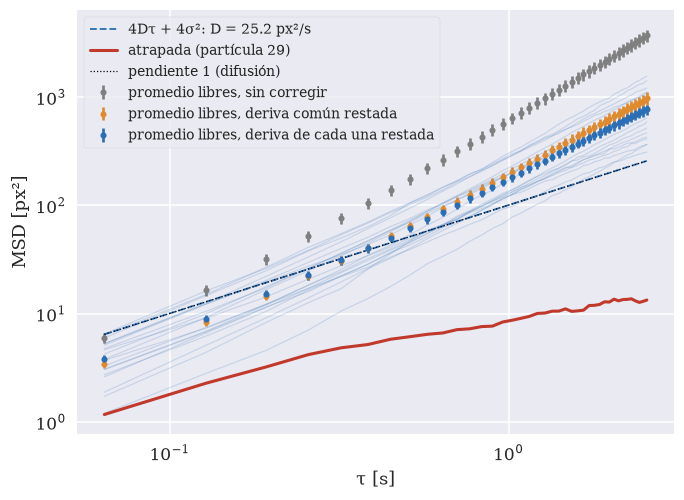

In [8]:
ax = graficar_msd(columnas(m_crudo, libre), u, color=GRIS, etiqueta='libres, sin corregir', por_particula=False)
graficar_msd(columnas(m_comun, libre), u, ax=ax, color=NARANJA, etiqueta='libres, deriva común restada', por_particula=False)
graficar_msd(columnas(m, libre), u, ax=ax, D=D_prom, etiqueta='libres, deriva de cada una restada')
for k in np.flatnonzero(atrapada):
    ax.plot(m['tau'], m['msd'][:, k], '-', color=ROJO, lw=2, label='atrapada (partícula %s)' % ids[k])
tau = m['tau'][np.isfinite(m['tau'])]
ax.plot(tau, 4 * D_prom * tau, ':', color='k', lw=0.8, label='pendiente 1 (difusión)')
ax.legend(fontsize=9);

- D se ajusta en los primeros `N_AJUSTE` retardos (τ ≲ 0.26 s). A τ ≳ 0.5 s el MSD de las libres sigue curvándose hacia arriba: la velocidad de cada bead **cambia** a lo largo de su recorrido y restar una recta no la saca del todo. A τ corto ese resto es despreciable frente a $4D\tau$.
- Si la ordenada sale **negativa**, el blur por exposición ($-4DW/3$) le gana al ruido de localización ($4\sigma^2$): no se puede despejar $\sigma$ sin la exposición $W$ (el MP4 no la guarda). D sale igual de la pendiente.

## 4. Desplazamientos (libres)

Si el movimiento es browniano, los desplazamientos a un retardo fijo son gaussianos, con varianza $2D\tau$ por eje.

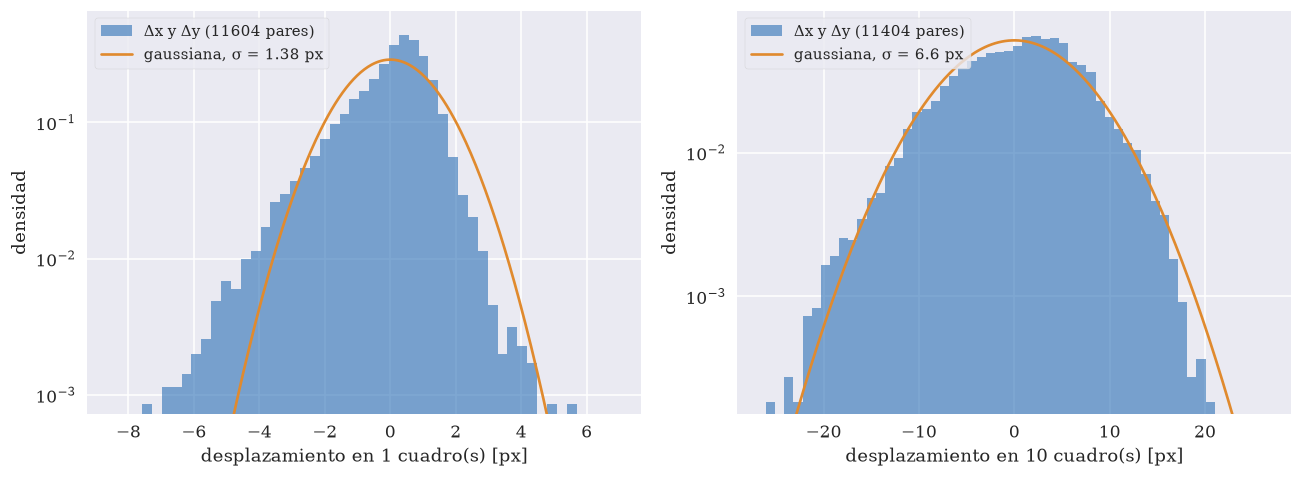

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
graficar_histograma(t, Xs[:, libre], Ys[:, libre], u, retardo=1, ax=axs[0])
graficar_histograma(t, Xs[:, libre], Ys[:, libre], u, retardo=10, ax=axs[1])
plt.tight_layout()

## 5. Bead atrapada

Posiciones respecto de su centro. En una trampa armónica $\langle x^2 \rangle = k_BT/\kappa$: con la escala, esto da la rigidez $\kappa$ (análisis completo, con correcciones de ruido y blur: `pinzas.trampa`).

partícula 29: 245 cuadros, σx = 3.3 px, σy = 1.02 px, MSD de meseta ≈ 13.2 px² (≈ 2(σx² + σy²) = 23.8)


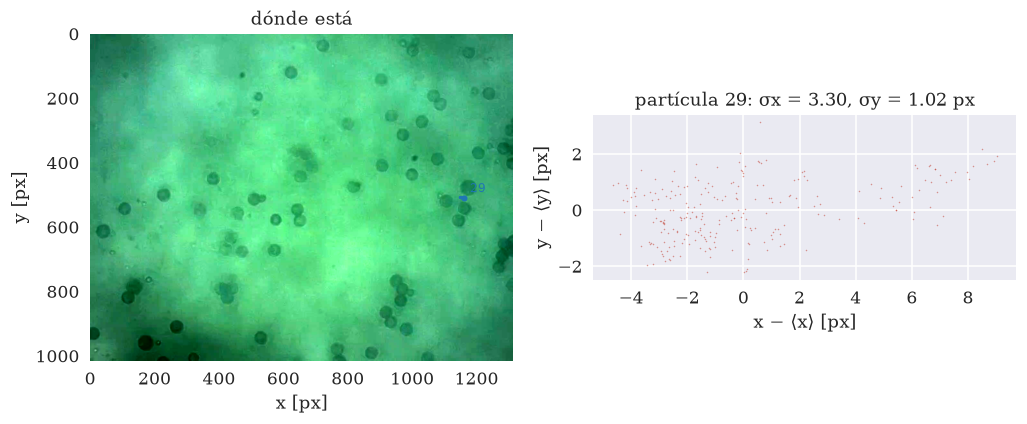

In [10]:
if atrapada.any():
    fig, axs = plt.subplots(1, 1 + atrapada.sum(), figsize=(5 + 4.5 * atrapada.sum(), 4.5))
    axs = np.atleast_1d(axs)
    for a, k in zip(axs[1:], np.flatnonzero(atrapada)):
        dx, dy = X[:, k] - np.nanmean(X[:, k]), Y[:, k] - np.nanmean(Y[:, k])
        a.plot(dx, dy, '.', ms=2, color=ROJO, alpha=0.5)
        a.set_aspect('equal'); a.set_xlabel('x − ⟨x⟩ [%s]' % u); a.set_ylabel('y − ⟨y⟩ [%s]' % u)
        a.set_title('partícula %s: σx = %.2f, σy = %.2f %s' % (ids[k], np.nanstd(dx), np.nanstd(dy), u))
        print('partícula %s: %d cuadros, σx = %.3g %s, σy = %.3g %s, MSD de meseta ≈ %.3g %s² (≈ 2(σx² + σy²) = %.3g)'
              % (ids[k], np.isfinite(dx).sum(), np.nanstd(dx), u, np.nanstd(dy), u, np.nanmean(m['msd'][-5:, k]), u,
                 2 * (np.nanvar(dx) + np.nanvar(dy))))
    graficar_trayectorias(datos, Xp[:, atrapada], Yp[:, atrapada], idp[atrapada], ax=axs[0], titulo='dónde está')
    plt.tight_layout()
else:
    print('no hay beads atrapadas (ninguna con α < %.1f)' % ALFA_ATRAPADA)

## 6. Escala

Si el video no tiene escala, D sale en px²/s. Con el diámetro de las beads se puede estimar la escala de dos maneras independientes y ver si coinciden:

1. **Por difusión:** $D_{\mathrm{teo}} = k_BT/(6\pi\eta R)$ → escala $= \sqrt{D_{\mathrm{teo}}/D_{\mathrm{px}}}$.
2. **Por tamaño:** diámetro en µm / diámetro aparente en px (2 × el *Radio* de B5).

Supuestos editables: diámetro, temperatura y viscosidad (agua). Para el valor de verdad hay que grabar una retícula y poner la escala en B8 (*Escala nm/px*).

In [11]:
DIAMETRO_UM = 3.0      # SUPUESTO: diámetro de las beads
T, ETA = 296.15, 0.93e-3
RADIO_PX = datos['parametros']['bloques'].get('b5_realce', {}).get('Radio', np.nan)
Dt = D_teorico(DIAMETRO_UM, T, ETA)
print('D teórico (%.1f µm, %.1f °C, η = %.2f mPa·s) = %.3f µm²/s' % (DIAMETRO_UM, T - 273.15, ETA * 1e3, Dt))
if u == 'px':
    e1 = np.sqrt(Dt / D_prom) * 1e3
    e2 = DIAMETRO_UM / (2 * RADIO_PX) * 1e3
    print('escala por difusión: %.0f nm/px  |  por tamaño (radio aparente %.0f px): %.0f nm/px' % (e1, RADIO_PX, e2))
else:
    print('D medido / D teórico = %.2f' % (D_prom / Dt))

D teórico (3.0 µm, 23.0 °C, η = 0.93 mPa·s) = 0.155 µm²/s
escala por difusión: 79 nm/px  |  por tamaño (radio aparente 17 px): 88 nm/px
